# Fenicsx EF verification of the damage problem : sinusoidal case

In [1]:
# --------------------
# Imports
# --------------------
from mpi4py import MPI
import dolfinx # FEM in python
import matplotlib.pyplot as plt
import ufl # variational formulations
import numpy as np
import gmsh
import basix.ufl
import dolfinx.fem as fem
import dolfinx.fem.petsc
import math
import dolfinx.io.gmsh as gmshio
import dolfinx_mpc.utils
from dolfinx_mpc import LinearProblem
import utils 

import pyvista # visualisation in python notebook
pyvista.set_jupyter_backend("static")

%matplotlib inline

In [2]:
dolfinx.__version__

'0.10.0'

# Parameters

In [5]:
# -----------------------
# Geometrical parameters
# -----------------------
L = 1.0 # Size of the cube
k = 1000 # offset


# -----------------------
# Meshing parameters
# -----------------------
mesh_factor = 0.1 # Meshing refinement
mesh_order = 2 # Order of interpolation for the test functions

# Mesh

In [6]:
mesh_size = mesh_factor * L
mesh_comm = MPI.COMM_WORLD
model_rank = 0

# -----------------------
# Init
# -----------------------
gmsh.initialize()
model = gmsh.model()
model.add("3D_sin")
model.setCurrent("3D_sin")

gdim = 3

# -------------------------
# Geometry (cube of size L)
# -------------------------
cube = model.occ.addBox(-L/2, -L/2, -L/2, L, L, L)
model.occ.synchronize()

In [7]:
# -------------------------------
# Classification of volumes (only matrix)
# -------------------------------
volumes = model.getEntities(dim=gdim)
matrix_vol = []

def classify_volume(dim, tag):
    return "matrix"


for dim, tag in volumes:
    label = classify_volume(dim, tag)
    if label == "matrix":
        matrix_vol.append(tag)

# --------------------------
# Add physical tag for bulk
# --------------------------
model.addPhysicalGroup(gdim, matrix_vol, tag=1)
model.setPhysicalName(gdim, 1, "matrix")

In [10]:
# -----------------------------------------------------------------------------
# Classification of boundary surfaces using their spatial location
# -----------------------------------------------------------------------------
surfaces = gmsh.model.getEntities(dim=gdim-1)

top_surfaces = []
bottom_surfaces = []
right_surfaces = []
left_surfaces = []
front_surfaces = []
back_surfaces = []


xmin_domain, ymin_domain, zmin_domain = -L/2, -L/2, -L/2
xmax_domain, ymax_domain, zmax_domain = L/2, L/2, L/2

eps = 1e-5 # Tolerance for surface classification

for dim, s in surfaces:
    
    xmin, ymin, zmin, xmax, ymax, zmax = gmsh.model.getBoundingBox(dim, s)

    cx = 0.5 * (xmin + xmax)
    cy = 0.5 * (ymin + ymax)
    cz = 0.5 * (zmin + zmax)

    # --- X faces
    if np.isclose(cx, xmin_domain, atol=eps):
        left_surfaces.append(s)

    elif np.isclose(cx, xmax_domain, atol=eps):
        right_surfaces.append(s)

    # --- Y faces
    elif np.isclose(cy, ymin_domain, atol=eps):
        bottom_surfaces.append(s)

    elif np.isclose(cy, ymax_domain, atol=eps):
        top_surfaces.append(s)

    # --- Z faces
    elif np.isclose(cz, zmin_domain, atol=eps):
        back_surfaces.append(s)

    else:
        front_surfaces.append(s)


# ---------------------------------------
# Add physical tag for boundary surfaces
# ---------------------------------------
gmsh.model.addPhysicalGroup(gdim-1, top_surfaces, 1)
gmsh.model.setPhysicalName(gdim-1, 1, "top_surface")

gmsh.model.addPhysicalGroup(gdim-1, bottom_surfaces, 2)
gmsh.model.setPhysicalName(gdim-1, 2, "bottom_surface")

gmsh.model.addPhysicalGroup(gdim-1, left_surfaces, 3)
gmsh.model.setPhysicalName(gdim-1, 3, "left_surface")

gmsh.model.addPhysicalGroup(gdim-1, right_surfaces, 4)
gmsh.model.setPhysicalName(gdim-1, 4, "right_surface")

gmsh.model.addPhysicalGroup(gdim-1, front_surfaces, 5)
gmsh.model.setPhysicalName(gdim-1, 5, "front_surface")

gmsh.model.addPhysicalGroup(gdim-1, back_surfaces, 6)
gmsh.model.setPhysicalName(gdim-1, 6, "back_surface")

In [12]:
# -----------------------
# Meshing
# -----------------------
gmsh.option.setNumber("Mesh.CharacteristicLengthMin", mesh_size)
gmsh.option.setNumber("Mesh.CharacteristicLengthMax", mesh_size)
model.mesh.generate(gdim)
gmsh.option.setNumber("General.Terminal", 1)
model.mesh.setOrder(mesh_order)
gmsh.option.setNumber("General.Terminal", 0)

Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 10%] Meshing curve 2 (Line)
Info    : [ 20%] Meshing curve 3 (Line)
Info    : [ 30%] Meshing curve 4 (Line)
Info    : [ 40%] Meshing curve 5 (Line)
Info    : [ 50%] Meshing curve 6 (Line)
Info    : [ 60%] Meshing curve 7 (Line)
Info    : [ 60%] Meshing curve 8 (Line)
Info    : [ 70%] Meshing curve 9 (Line)
Info    : [ 80%] Meshing curve 10 (Line)
Info    : [ 90%] Meshing curve 11 (Line)
Info    : [100%] Meshing curve 12 (Line)
Info    : Done meshing 1D (Wall 0.00272468s, CPU 0.00391s)
Info    : Meshing 2D...
Info    : [  0%] Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : [ 20%] Meshing surface 2 (Plane, Frontal-Delaunay)
Info    : [ 40%] Meshing surface 3 (Plane, Frontal-Delaunay)
Info    : [ 60%] Meshing surface 4 (Plane, Frontal-Delaunay)
Info    : [ 70%] Meshing surface 5 (Plane, Frontal-Delaunay)
Info    : [ 90%] Meshing surface 6 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.0299686s, 

In [13]:
# ---------------------------
# Import the mesh in dolfinx
# ---------------------------
domain, cell_tags, facet_tags, *rest = gmshio.model_to_mesh(
    model, mesh_comm, model_rank, gdim=gdim
)
domain.name = "3D_sin"
cell_tags.name = f"{domain.name}_cells"
facet_tags.name = f"{domain.name}_facets"
gmsh.finalize()

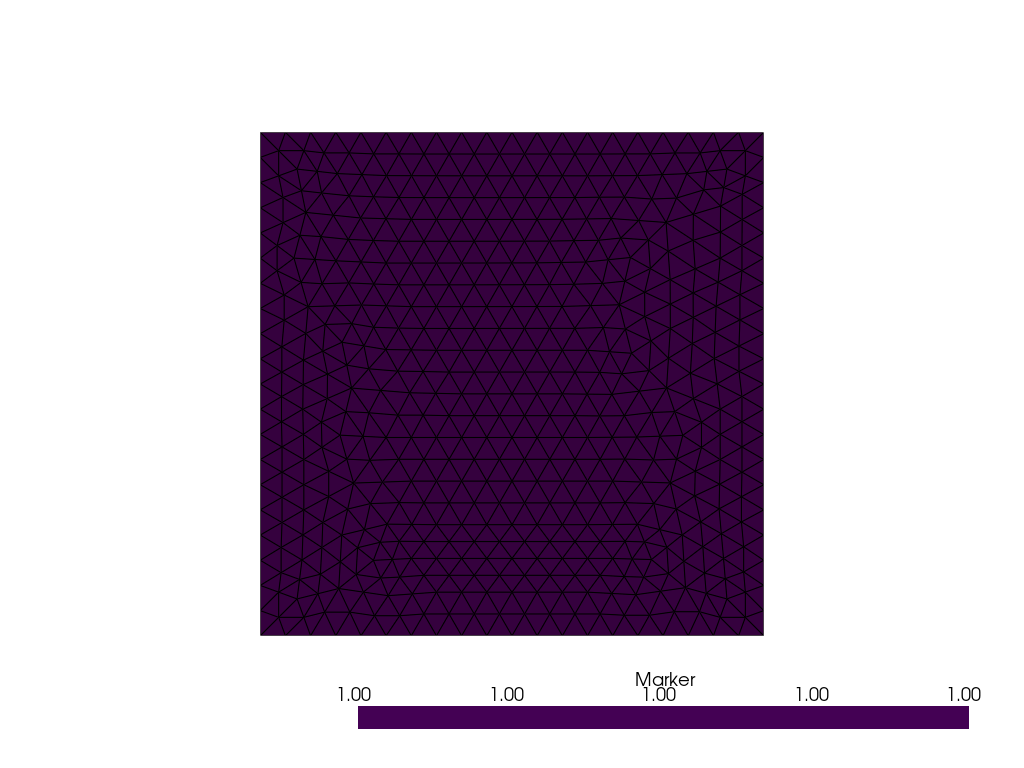

In [14]:
# -----------------------
# Pyvista visualization
# -----------------------
topology, cells, geometry = dolfinx.plot.vtk_mesh(domain)
function_grid = pyvista.UnstructuredGrid(topology, cells, geometry)
function_grid["Marker"] = cell_tags.values

slice_z0 = function_grid.slice(normal=(0, 0, 1), origin=(0, 0, 0))

vmin = function_grid["Marker"].min()
vmax = function_grid["Marker"].max()

plotter = pyvista.Plotter()
plotter.add_mesh(function_grid, scalars="Marker",
                 show_edges=True,
                 clim=[vmin, vmax])
plotter.view_xy()          
plotter.show()

# Define integral over the different domains

In [15]:
dx = ufl.Measure("dx", domain=domain, subdomain_data=cell_tags)
ds = ufl.Measure("ds", domain=domain, subdomain_data=facet_tags)
one = dolfinx.fem.Constant(domain,dolfinx.default_scalar_type(1.))

In [16]:
# ------------------------------------------------
# Verification of the total volume of the domain
# ------------------------------------------------
volume_domain = utils.assemble_scalar(dolfinx.fem.form(one * dx(1)))
volume_domain

1.0000000000000038

# Define the damage problem

In [17]:
V = fem.functionspace(domain, ("Lagrange", mesh_order)) # ! Same order of interpolation for the test functions as for the mesh

y = ufl.SpatialCoordinate(domain) # Spatial coordinates

# ----------------------------------------------------
# Sinusoidal functions of the z component of space
# ----------------------------------------------------
damage_an = ufl.sin(2 * np.pi / L * y[2])
damage_second = -(4*(np.pi**2)/(L**2))*damage_an
A = k*ufl.sin(2*y[2]*np.pi/L) + k +1
B = (A*damage_an) - damage_second


# --------------------------------------------------------------------------------------------------
# Equivalent of "strain" and "stress" objects but for the damage problem (eps and sigma of dim 1x4)
# --------------------------------------------------------------------------------------------------
def eps(d):
    # eps = (grad(d), d)
    return ufl.as_vector((ufl.grad(d)[0], ufl.grad(d)[1], ufl.grad(d)[2], d))


def sigma(eps, A):
    # sigma = C.eps with C = Identity with A on the 4th component 
    return ufl.as_vector((eps[0], eps[1], eps[2], A*eps[3]))



# Trial and test function
d = ufl.TrialFunction(V)
d_bar = ufl.TestFunction(V)


# Bilinear form
bilinear_form = ufl.dot(sigma(eps(d), A), eps(d_bar))*dx(1)

# Linear form
linear_form = ufl.dot(ufl.as_vector([0,0,0,B]), eps(d_bar))*dx(1)

# Boundary conditions :

tutorial : https://bleyerj.github.io/comet-fenicsx/tours/homogenization/periodic_elasticity/periodic_elasticity.html

In [18]:
# Cartesian vectors
a1 = np.array([1,0,0])  # first vector generating periodicity
a2 = np.array([0,1,0])  # second vector generating periodicity
a3 = np.array([0,0,1])  # third vector generating periodicity

In [22]:
# --------------------------------------------------
# Periodicity conditions on the boundary surfaces
# --------------------------------------------------

def periodic_relation_left_right(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - a1[0]
    out_x[1] = x[1] - a1[1]
    out_x[2] = x[2] - a1[2]
    return out_x


def periodic_relation_bottom_top(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - a2[0]
    out_x[1] = x[1] - a2[1]
    out_x[2] = x[2] - a2[2]
    return out_x


def periodic_relation_back_front(x):
    out_x = np.zeros(x.shape)
    out_x[0] = x[0] - a3[0]
    out_x[1] = x[1] - a3[1]
    out_x[2] = x[2] - a3[2]
    return out_x


mpc = dolfinx_mpc.MultiPointConstraint(V)

mpc.create_periodic_constraint_topological(
    V, facet_tags, 1, periodic_relation_bottom_top, bcs=[]
)

mpc.create_periodic_constraint_topological(
    V, facet_tags, 4, periodic_relation_left_right,bcs=[]
)

mpc.create_periodic_constraint_topological(
    V, facet_tags, 5, periodic_relation_back_front,bcs=[]
)


mpc.finalize()

In [23]:
# -------------------------------------
# Final problem definition
# -------------------------------------
v = fem.Function(mpc.function_space, name="Periodic_fluctuation")
problem = LinearProblem(
    bilinear_form,
    linear_form,
    mpc,
    u=v,
    petsc_options={"ksp_type": "preonly", "pc_type": "lu"},
)

In [24]:
# --------------------------
# Solution computation
# --------------------------
d_solution = problem.solve()

In [25]:
# -----------------
# Paraview export
# -----------------
with dolfinx.io.XDMFFile(domain.comm, "damage.xdmf", "w") as file:
    file.write_mesh(domain)
    file.write_function(d_solution)